# E2: Model dùng Static + forcing khí tượng (CAMELS trong Caravan)

Thí nghiệm này tương ứng với model **"Global LSTM without static features"** trong Kratzert et al. (2019, WRR), có NSE trung vị 0.63 trên 531 lưu vực CAMELS.

| Thiết lập | Giá trị |
|---|---|
| Đầu vào | 22 biến khí tượng ERA5-Land, có thuộc tính tĩnh |
| Đầu ra | `streamflow` (mm/ngày) của ngày cuối cửa sổ |
| Cửa sổ | 365 ngày, stride 1 |
| Train / Val / Test | 01/10/1980–30/09/1990 / 01/10/1990–30/09/1995 / 01/10/1995–30/09/2010 |
| Model | LSTM 256 cell, dropout 0.4, 1 lớp Linear ở cuối |
| Loss | NSE* (trung bình NSE có trọng số theo từng lưu vực) |

**Các bước trong notebook**

1. Cấu hình chung (**bạn chỉ cần sửa ô này**)
2. Kiểm tra môi trường
3. Chuyển CSV → netCDF (chỉ chạy 1 lần)
4. Kiểm tra chất lượng và chọn lưu vực
5. Tạo file cấu hình NeuralHydrology
6. Train
7. Xem quá trình train, chọn epoch tốt nhất theo tập validation
8. Đánh giá trên tập test
9. Xem hydrograph của một số lưu vực

**Cách dùng:** lần đầu để `QUICK_TEST = True` để chạy thử nhanh (20 lưu vực, 2 epoch, LSTM nhỏ), kiểm tra mọi bước không lỗi. Sau đó đổi `QUICK_TEST = False`, chạy lại từ ô 1 để train thật. Bước 3 không cần chạy lại.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # để tránh lỗi "OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized."

In [2]:
from pathlib import Path

CARAVAN_ROOT = Path(r"D:\Dev\ANCU Project\Caravan-csv")
QUICK_TEST = False

RESULT_DIR = Path("result")
SUBSET = "camels"
SEED = 42

DYNAMIC_INPUTS = [
    "total_precipitation_sum",
    "temperature_2m_min", "temperature_2m_mean", "temperature_2m_max",
    "dewpoint_temperature_2m_min", "dewpoint_temperature_2m_mean", "dewpoint_temperature_2m_max",
    "surface_net_solar_radiation_mean", "surface_net_solar_radiation_max",
    "surface_net_thermal_radiation_min", "surface_net_thermal_radiation_mean", "surface_net_thermal_radiation_max",
    "surface_pressure_min", "surface_pressure_mean", "surface_pressure_max",
    "u_component_of_wind_10m_min", "u_component_of_wind_10m_mean", "u_component_of_wind_10m_max",
    "v_component_of_wind_10m_min", "v_component_of_wind_10m_mean", "v_component_of_wind_10m_max",
    "potential_evaporation_sum_FAO_PENMAN_MONTEITH",
]
TARGET = "streamflow"
STATIC_ATTRIBUTES = [
    # Khí hậu
    "p_mean", "pet_mean_FAO_PM", "aridity_FAO_PM", "seasonality_FAO_PM", "frac_snow",
    "high_prec_freq", "high_prec_dur", "low_prec_freq", "low_prec_dur",
    # Địa hình
    "ele_mt_sav", "slp_dg_sav", "area",
    # Thảm phủ
    "for_pc_sse", "crp_pc_sse", "pst_pc_sse", "urb_pc_sse",
    # Đất
    "cly_pc_sav", "slt_pc_sav", "snd_pc_sav", "soc_th_sav", "swc_pc_syr",
    # Địa chất, nước ngầm
    "kar_pc_sse", "gwt_cm_sav",
    # Hồ và tác động con người
    "lka_pc_sse", "ire_pc_sse", "dor_pc_pva",
]

PERIODS = {
    "train":      ("1980-10-01", "1990-09-30"),
    "validation": ("1990-10-01", "1995-09-30"),
    "test":       ("1995-10-01", "2010-09-30"),
}
SEQ_LENGTH = 365
MIN_VALID_YEARS = {"train": 5, "validation": 2, "test": 3}   # số năm có nhãn tối thiểu để giữ lưu vực
MODEL = 'gru'
model_tag = {"cudalstm": "lstm"}.get(MODEL, MODEL)
# Siêu tham số
if QUICK_TEST:
    EXPERIMENT = "e2_" + model_tag +"_forcing_only_QUICK"
    N_BASINS_QUICK = 20
    HIDDEN_SIZE, EPOCHS = 32, 2
    LEARNING_RATE = {0: 1e-3}
else:
    EXPERIMENT = "e2_" + model_tag +"static_forcing"
    EPOCHS = 5
    HIDDEN_SIZE = 256
    D_MODEL, N_HEADS, N_LAYERS, DIM_FF = 64, 4, 4,256
    LEARNING_RATE = {0: 1e-3} if MODEL != "transformer" else {0: 1e-4}                       # trong nhánh QUICK_TEST
    LEARNING_RATE = ({0: 1e-3, 10: 5e-4, 25: 1e-4} if MODEL != "transformer"
                 else {0: 1e-4, 10: 5e-5, 25: 1e-5})                                      # trong nhánh train thật
BATCH_SIZE = 256 if MODEL != "transformer" else 128
OUTPUT_DROPOUT = 0.4 if MODEL != "transformer" else 0.1

CSV_DIR = CARAVAN_ROOT / "timeseries" / "csv" / SUBSET
NC_DIR = CARAVAN_ROOT / "timeseries" / "netcdf" / SUBSET
E2_DIR = RESULT_DIR / "e2"
E2_DIR.mkdir(parents=True, exist_ok=True)

print("CSV:", CSV_DIR, "| ton tai:", CSV_DIR.is_dir())
print("Ket qua se luu tai:", E2_DIR.resolve())
if QUICK_TEST:
    print("\n*** QUICK_TEST = True: day chi la lan chay thu, KHONG phai ket qua that ***")

CSV: D:\Dev\ANCU Project\Caravan-csv\timeseries\csv\camels | ton tai: True
Ket qua se luu tai: D:\Dev\ANCU Project\main\src\result\e2


In [3]:
import sys, platform, importlib
import numpy as np
import pandas as pd
import torch

print("OS:", platform.platform(), "| Python:", sys.version.split()[0])
for pkg in ["torch", "neuralhydrology", "pandas", "numpy", "xarray", "netCDF4"]:
    m = importlib.import_module(pkg)
    print(f"  {pkg}: {getattr(m, '__version__', 'installed')}")

if torch.cuda.is_available():
    DEVICE = "cuda:0"
    x = torch.randn(1024, 1024, device=DEVICE); _ = (x @ x).sum().item()
    print("GPU:", torch.cuda.get_device_name(0), "| CUDA", torch.version.cuda, "-> OK")
else:
    DEVICE = "cpu"
    print("KHONG thay GPU, se chay tren CPU (rat cham). Kiem tra lai ban PyTorch.")

OS: Windows-10-10.0.26200-SP0 | Python: 3.11.17
  torch: 2.11.0+cu128
  neuralhydrology: installed
  pandas: 3.0.6
  numpy: 2.4.6
  xarray: 2026.9.0
  netCDF4: 1.7.5
GPU: NVIDIA GeForce RTX 5060 Ti | CUDA 12.8 -> OK


In [6]:
import xarray as xr
from tqdm import tqdm
from neuralhydrology.datasetzoo.caravan import load_caravan_attributes

warmup_start = pd.Timestamp(PERIODS["train"][0]) - pd.Timedelta(days=SEQ_LENGTH - 1)
test_end = pd.Timestamp(PERIODS["test"][1])

rows = []
for nc in tqdm(sorted(NC_DIR.glob("*.nc")), desc="Kiem tra luu vuc"):
    with xr.open_dataset(nc) as ds:
        df = ds[DYNAMIC_INPUTS + [TARGET]].to_dataframe()
    rec = {"gauge_id": nc.stem}
    for p, (s, e) in PERIODS.items():
        rec[f"{p}_years"] = round(df.loc[s:e, TARGET].notna().sum() / 365.25, 2)
    rec["forcing_nan_days"] = int(df.loc[warmup_start:test_end, DYNAMIC_INPUTS].isna().any(axis=1).sum())
    rec["forcing_covers_period"] = bool(df.index.min() <= warmup_start and df.index.max() >= test_end)
    rows.append(rec)

qc = pd.DataFrame(rows).set_index("gauge_id")
reasons = []
for gid, r in qc.iterrows():
    why = [f"{p}<{MIN_VALID_YEARS[p]}nam" for p in PERIODS if r[f"{p}_years"] < MIN_VALID_YEARS[p]]
    if r.forcing_nan_days > 0: why.append(f"forcing thieu {r.forcing_nan_days} ngay")
    if not r.forcing_covers_period: why.append("forcing khong du dai")
    reasons.append("; ".join(why))
qc["exclude_reason"] = reasons
qc["selected"] = qc["exclude_reason"] == ""
qc.to_csv(E2_DIR / "basin_qc.csv")

selected = qc.index[qc.selected].tolist()
print(f"Tong: {len(qc)} luu vuc | Giu lai: {len(selected)} | Loai: {(~qc.selected).sum()}")
print(qc[[f"{p}_years" for p in PERIODS]].describe().round(2).loc[["min", "50%", "max"]])
if (~qc.selected).any():
    print("\nCac luu vuc bi loai:")
    print(qc.loc[~qc.selected, "exclude_reason"].to_string())

if QUICK_TEST:
    rng = np.random.default_rng(SEED)
    selected = sorted(rng.choice(selected, size=min(N_BASINS_QUICK, len(selected)), replace=False).tolist())
    print(f"\nQUICK_TEST: chi dung {len(selected)} luu vuc")

BASIN_FILE = E2_DIR / ("basins_e2_quick.txt" if QUICK_TEST else "basins_e2.txt")

attrs = load_caravan_attributes(CARAVAN_ROOT, subdataset=SUBSET)
missing_cols = [a for a in STATIC_ATTRIBUTES if a not in attrs.columns]
if missing_cols:
    raise ValueError(f"Khong tim thay cac thuoc tinh static: {missing_cols}")
attrs = attrs.loc[attrs.index.intersection(selected), STATIC_ATTRIBUTES]

no_attr = sorted(set(selected) - set(attrs.index))
has_nan = attrs.index[attrs.isna().any(axis=1)].tolist()
zero_std = [a for a in STATIC_ATTRIBUTES if attrs[a].std() == 0]
print(f"Thuoc tinh tinh: {len(STATIC_ATTRIBUTES)} | luu vuc thieu thuoc tinh: {len(no_attr)} "
      f"| co NaN: {len(has_nan)} | thuoc tinh co std = 0: {zero_std}")
if zero_std:
    raise ValueError(f"Bo cac thuoc tinh khong doi nay khoi STATIC_ATTRIBUTES: {zero_std}")

selected = [b for b in selected if b not in set(no_attr) | set(has_nan)]
BASIN_FILE.write_text("\n".join(selected))
attrs.loc[selected].describe().T.round(3).to_csv(E2_DIR / "static_attributes_summary.csv")
print(f"Con lai {len(selected)} luu vuc")

Kiem tra luu vuc: 100%|██████████| 671/671 [06:06<00:00,  1.83it/s]

Tong: 671 luu vuc | Giu lai: 638 | Loai: 33
     train_years  validation_years  test_years
min         1.00               4.0        11.0
50%         9.75               5.0        15.0
max        10.00               5.0        15.0

Cac luu vuc bi loai:
gauge_id
camels_01350080    train<5nam
camels_01594950    train<5nam
camels_02096846    train<5nam
camels_02193340    train<5nam
camels_02198100    train<5nam
camels_02215100    train<5nam
camels_02363000    train<5nam
camels_02427250    train<5nam
camels_02464360    train<5nam
camels_03050000    train<5nam
camels_03338780    train<5nam
camels_04115265    train<5nam
camels_04213075    train<5nam
camels_05062500    train<5nam
camels_05592575    train<5nam
camels_06188000    train<5nam
camels_06221400    train<5nam
camels_06440200    train<5nam
camels_06906800    train<5nam
camels_06934000    train<5nam
camels_07263295    train<5nam
camels_07359610    train<5nam
camels_07362587    train<5nam
camels_08155200    train<5nam
camels_09107000  

In [7]:
fmt = lambda d: pd.Timestamp(d).strftime("%d/%m/%Y")
lr_yaml = "\n".join(f"  {k}: {v}" for k, v in LEARNING_RATE.items())
inputs_yaml = "\n".join(f"  - {v}" for v in DYNAMIC_INPUTS)
basin_path = BASIN_FILE.resolve().as_posix()

if MODEL == "cudalstm":
    model_lines = [
        "model: cudalstm",
        "head: regression",
        "output_activation: linear",
        f"hidden_size: {HIDDEN_SIZE}",
        "initial_forget_bias: 3",
        f"output_dropout: {OUTPUT_DROPOUT}",
    ]
elif MODEL == "gru":
    model_lines = [
        "model: gru",
        "head: regression",
        "output_activation: linear",
        f"hidden_size: {HIDDEN_SIZE}",
        f"output_dropout: {OUTPUT_DROPOUT}",
    ]
else:
    model_lines = [
        "model: transformer",
        "head: regression",
        "output_activation: linear",
        "dynamics_embedding:",
        "  type: fc",
        f"  hiddens: [{D_MODEL}]",
        "  activation: tanh",
        "  dropout: 0.0",
        f"transformer_nlayers: {N_LAYERS}",
        f"transformer_nheads: {N_HEADS}",
        f"transformer_dim_feedforward: {DIM_FF}",
        "transformer_dropout: 0.1",
        "transformer_positional_encoding_type: sum",
        "transformer_positional_dropout: 0.0",
        f"output_dropout: {OUTPUT_DROPOUT}",
    ]
model_yaml = "\n".join(model_lines)
static_yaml = "static_attributes:\n" + "\n".join(f"  - {a}" for a in STATIC_ATTRIBUTES)
config_text = f"""# --- Thi nghiem ---
experiment_name: {EXPERIMENT}
run_dir: {(E2_DIR / 'runs').resolve().as_posix()}
seed: {SEED}
device: {DEVICE}

# --- Luu vuc va moc chia (A) ---
train_basin_file: {basin_path}
validation_basin_file: {basin_path}
test_basin_file: {basin_path}
train_start_date: {fmt(PERIODS['train'][0])}
train_end_date: {fmt(PERIODS['train'][1])}
validation_start_date: {fmt(PERIODS['validation'][0])}
validation_end_date: {fmt(PERIODS['validation'][1])}
test_start_date: {fmt(PERIODS['test'][0])}
test_end_date: {fmt(PERIODS['test'][1])}

# --- Du lieu ---
dataset: caravan
data_dir: {CARAVAN_ROOT.resolve().as_posix()}
dynamic_inputs:
{inputs_yaml}
target_variables:
  - {TARGET}
clip_targets_to_zero:
  - {TARGET}
{static_yaml}

# --- Cua so truot ---
seq_length: {SEQ_LENGTH}
predict_last_n: 1

# --- Model ---
{model_yaml}

# --- Train ---
optimizer: Adam
loss: NSE
learning_rate:
{lr_yaml}
batch_size: {BATCH_SIZE}
epochs: {EPOCHS}
clip_gradient_norm: 1
num_workers: 0

# --- Danh gia ---
validate_every: 1
metrics:
  - NSE
  - KGE
  - Alpha-NSE
  - Beta-NSE
  - Pearson-r
  - FHV
  - FLV

# --- Log ---
log_interval: 5
log_tensorboard: False
log_n_figures: 0
save_weights_every: 1
"""
CONFIG_FILE = E2_DIR / f"{EXPERIMENT}.yml"
CONFIG_FILE.write_text(config_text, encoding="utf-8")
print(config_text)
print("Da ghi:", CONFIG_FILE)

# --- Thi nghiem ---
experiment_name: e2_grustatic_forcing
run_dir: D:/Dev/ANCU Project/main/src/result/e2/runs
seed: 42
device: cuda:0

# --- Luu vuc va moc chia (A) ---
train_basin_file: D:/Dev/ANCU Project/main/src/result/e2/basins_e2.txt
validation_basin_file: D:/Dev/ANCU Project/main/src/result/e2/basins_e2.txt
test_basin_file: D:/Dev/ANCU Project/main/src/result/e2/basins_e2.txt
train_start_date: 01/10/1980
train_end_date: 30/09/1990
validation_start_date: 01/10/1990
validation_end_date: 30/09/1995
test_start_date: 01/10/1995
test_end_date: 30/09/2010

# --- Du lieu ---
dataset: caravan
data_dir: D:/Dev/ANCU Project/Caravan-csv
dynamic_inputs:
  - total_precipitation_sum
  - temperature_2m_min
  - temperature_2m_mean
  - temperature_2m_max
  - dewpoint_temperature_2m_min
  - dewpoint_temperature_2m_mean
  - dewpoint_temperature_2m_max
  - surface_net_solar_radiation_mean
  - surface_net_solar_radiation_max
  - surface_net_thermal_radiation_min
  - surface_net_thermal_radiation_me

In [8]:
from neuralhydrology.nh_run import start_run

runs_dir = E2_DIR / "runs"
before = set(runs_dir.glob(f"{EXPERIMENT}_*")) if runs_dir.exists() else set()
start_run(config_file=CONFIG_FILE)

new_runs = sorted(set(runs_dir.glob(f"{EXPERIMENT}_*")) - before)
RUN_DIR = new_runs[-1]
(E2_DIR / f"last_run_{EXPERIMENT}.txt").write_text(str(RUN_DIR.resolve()))
print("Run dir:", RUN_DIR)

2026-10-22 17:05:17,040: Logging to D:\Dev\ANCU Project\main\src\result\e2\runs\e2_grustatic_forcing_2210_170517\output.log initialized.
2026-10-22 17:05:17,041: ### Folder structure created at D:\Dev\ANCU Project\main\src\result\e2\runs\e2_grustatic_forcing_2210_170517
2026-10-22 17:05:17,041: ### Run configurations for e2_grustatic_forcing
2026-10-22 17:05:17,041: experiment_name: e2_grustatic_forcing
2026-10-22 17:05:17,041: run_dir: D:\Dev\ANCU Project\main\src\result\e2\runs\e2_grustatic_forcing_2210_170517
2026-10-22 17:05:17,042: seed: 42
2026-10-22 17:05:17,042: device: cuda:0
2026-10-22 17:05:17,042: train_basin_file: D:\Dev\ANCU Project\main\src\result\e2\basins_e2.txt
2026-10-22 17:05:17,043: validation_basin_file: D:\Dev\ANCU Project\main\src\result\e2\basins_e2.txt
2026-10-22 17:05:17,043: test_basin_file: D:\Dev\ANCU Project\main\src\result\e2\basins_e2.txt
2026-10-22 17:05:17,043: train_start_date: 1980-10-01 00:00:00
2026-10-22 17:05:17,043: train_end_date: 1990-09-30 0

Run dir: result\e2\runs\e2_grustatic_forcing_2210_170517
       val_loss  avg_loss     NSE     KGE  Alpha-NSE  Beta-NSE  Pearson-r      FHV       FLV  train_loss
epoch                                                                                                   
1        0.0345    0.0345  0.4667  0.4725     0.6372   -0.0060     0.7400 -38.9549  -39.3223      0.0427
2        0.0333    0.0333  0.4694  0.5160     0.7195    0.0285     0.7442 -29.0641 -107.6610      0.0328
3        0.0332    0.0332  0.4858  0.5258     0.7171    0.0062     0.7371 -28.4668  -61.3526      0.0297
4        0.0338    0.0338  0.4712  0.5300     0.7377   -0.0118     0.7297 -25.8620 -200.8302      0.0279
5        0.0326    0.0326  0.4810  0.5282     0.6798   -0.0257     0.7293 -31.6886  -24.9641      0.0270

Epoch tot nhat (NSE trung vi val cao nhat): 3  ->  NSE = 0.486


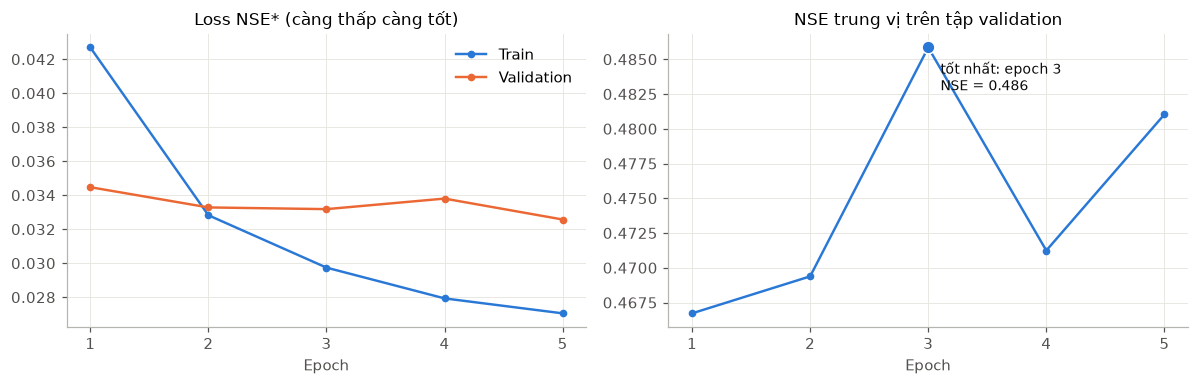

In [9]:
import re
import matplotlib.pyplot as plt

# Màu và kiểu đường thống nhất cho mọi biểu đồ
C_BLUE, C_ORANGE, C_INK, C_MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.labelcolor": C_MUTED, "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.titlesize": 11, "lines.linewidth": 1.6, "legend.frameon": False,
})

if "RUN_DIR" not in globals():
    RUN_DIR = Path((E2_DIR / f"last_run_{EXPERIMENT}.txt").read_text().strip())
RUN_DIR = Path(RUN_DIR)
print("Run dir:", RUN_DIR)

num = r"(-?\d+(?:\.\d+)?(?:e-?\d+)?|nan)"
train_rows, val_rows = {}, {}
for line in (RUN_DIR / "output.log").read_text(encoding="utf-8").splitlines():
    m = re.search(rf"Epoch (\d+) average loss: .*?avg_total_loss: {num}", line)
    if m:
        train_rows[int(m.group(1))] = float(m.group(2))
    m = re.search(rf"Epoch (\d+) average validation loss: {num} -- Median validation metrics: (.*)", line)
    if m:
        metrics = dict(re.findall(rf"([\w-]+): {num}", m.group(3)))
        val_rows[int(m.group(1))] = {"val_loss": float(m.group(2)), **{k: float(v) for k, v in metrics.items()}}

hist = pd.DataFrame(val_rows).T.join(pd.Series(train_rows, name="train_loss"), how="outer").sort_index()
hist.index.name = "epoch"
nse_col = [c for c in hist.columns if c.endswith("NSE") and "Alpha" not in c and "Beta" not in c][0]
BEST_EPOCH = int(hist[nse_col].idxmax())
hist.to_csv(E2_DIR / f"{EXPERIMENT}_training_history.csv")
print(hist.round(4).to_string())
print(f"\nEpoch tot nhat (NSE trung vi val cao nhat): {BEST_EPOCH}  ->  NSE = {hist.loc[BEST_EPOCH, nse_col]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(hist.index, hist["train_loss"], color=C_BLUE, marker="o", ms=4, label="Train")
ax.plot(hist.index, hist["val_loss"], color=C_ORANGE, marker="o", ms=4, label="Validation")
ax.set_title("Loss NSE* (càng thấp càng tốt)"); ax.set_xlabel("Epoch"); ax.legend()
ax = axes[1]
ax.plot(hist.index, hist[nse_col], color=C_BLUE, marker="o", ms=4)
ax.scatter([BEST_EPOCH], [hist.loc[BEST_EPOCH, nse_col]], s=70, color=C_BLUE, edgecolor="white", zorder=3)
ax.annotate(f"tốt nhất: epoch {BEST_EPOCH}\nNSE = {hist.loc[BEST_EPOCH, nse_col]:.3f}",
            (BEST_EPOCH, hist.loc[BEST_EPOCH, nse_col]), textcoords="offset points", xytext=(8, -28),
            color=C_INK, fontsize=9)
ax.set_title("NSE trung vị trên tập validation"); ax.set_xlabel("Epoch")
for a in axes: a.xaxis.get_major_locator().set_params(integer=True)
plt.tight_layout(); plt.savefig(E2_DIR / f"{EXPERIMENT}_training_curves.png", dpi=150); plt.show()

Run dir: result\e2\runs\e2_grustatic_forcing_2210_170517
Cac epoch da luu trong so: [1, 2, 3, 4, 5]
Danh gia epoch: 3
2026-10-22 18:39:24,821: Using the model weights from result\e2\runs\e2_grustatic_forcing_2210_170517\model_epoch003.pt
# Evaluation: 100%|██████████| 638/638 [12:43<00:00,  1.20s/it]
2026-10-22 18:52:08,715: Stored metrics at result\e2\runs\e2_grustatic_forcing_2210_170517\test\model_epoch003\test_metrics.csv
2026-10-22 18:52:08,833: Stored results at result\e2\runs\e2_grustatic_forcing_2210_170517\test\model_epoch003\test_results.p
              NSE    KGE  Alpha-NSE  Beta-NSE  Pearson-r     FHV           FLV  n_luu_vuc  n_NSE_am
trung_vi    0.496  0.520      0.657     0.003      0.726 -33.650 -7.544600e+01        638        23
trung_binh  0.459  0.382      0.653     0.021      0.704 -32.731 -9.613233e+10        638        23

NSE trung vi tap test: 0.496  (paper, LSTM khong co thuoc tinh tinh: 0.63)


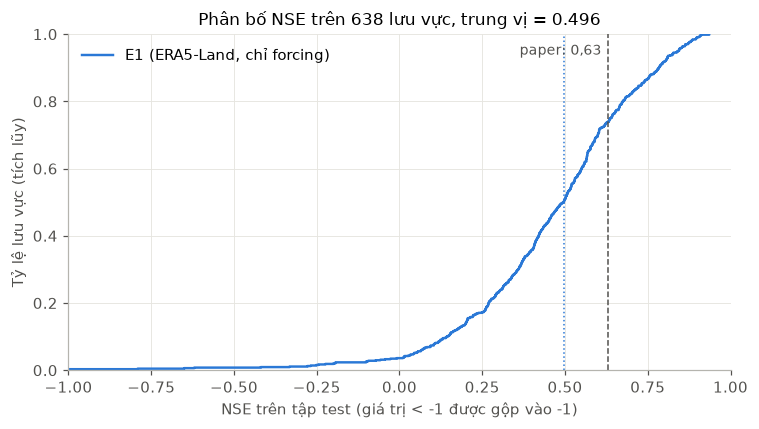

In [10]:
import pickle
from neuralhydrology.nh_run import eval_run
import re

# Lấy lần chạy mới nhất của đúng thí nghiệm hiện tại (không lẫn bản QUICK)
pat = re.compile(rf"^{re.escape(EXPERIMENT)}_\d{{4}}_\d{{6}}$")
runs = sorted([p for p in (E2_DIR / "runs").iterdir() if p.is_dir() and pat.match(p.name)],
              key=lambda p: p.stat().st_mtime)
RUN_DIR = runs[-1]
PAPER_REF = 0.74
saved = sorted(int(p.stem[-3:]) for p in RUN_DIR.glob("model_epoch*.pt"))
print("Run dir:", RUN_DIR)
print("Cac epoch da luu trong so:", saved)
if BEST_EPOCH not in saved:
    raise FileNotFoundError(f"Khong co model_epoch{BEST_EPOCH:03d}.pt trong {RUN_DIR}")
print("Danh gia epoch:", BEST_EPOCH)
eval_run(run_dir=RUN_DIR, period="test", epoch=BEST_EPOCH)

test_dir = RUN_DIR / "test" / f"model_epoch{BEST_EPOCH:03d}"
metrics = pd.read_csv(test_dir / "test_metrics.csv", dtype={"basin": str}).set_index("basin")
metrics.to_csv(E2_DIR / f"{EXPERIMENT}_test_metrics.csv")
with open(test_dir / "test_results.p", "rb") as fp:
    TEST_RESULTS = pickle.load(fp)

nse = metrics.filter(regex=r"(^|_)NSE$").iloc[:, 0]
summary = pd.DataFrame({
    "trung_vi": metrics.median(numeric_only=True),
    "trung_binh": metrics.mean(numeric_only=True),
}).T
summary["n_luu_vuc"] = len(metrics)
summary["n_NSE_am"] = int((nse < 0).sum())
summary.to_csv(E2_DIR / f"{EXPERIMENT}_test_summary.csv")
print(summary.round(3).to_string())
print(f"\nNSE trung vi tap test: {nse.median():.3f}  (paper, LSTM khong co thuoc tinh tinh: 0.63)")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.sort(nse.clip(lower=-1).values)
ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=C_BLUE, label="E1 (ERA5-Land, chỉ forcing)")
ax.axvline(0.63, color=C_MUTED, ls="--", lw=1)
ax.text(0.61, 0.97, "paper: 0,63", color=C_MUTED, fontsize=9, ha="right", va="top")
ax.axvline(nse.median(), color=C_BLUE, ls=":", lw=1)
ax.set_xlim(-1, 1); ax.set_ylim(0, 1)
ax.set_xlabel("NSE trên tập test (giá trị < -1 được gộp vào -1)"); ax.set_ylabel("Tỷ lệ lưu vực (tích lũy)")
ax.set_title(f"Phân bố NSE trên {len(nse)} lưu vực, trung vị = {nse.median():.3f}")
ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(E2_DIR / f"{EXPERIMENT}_test_nse_cdf.png", dpi=150); plt.show()

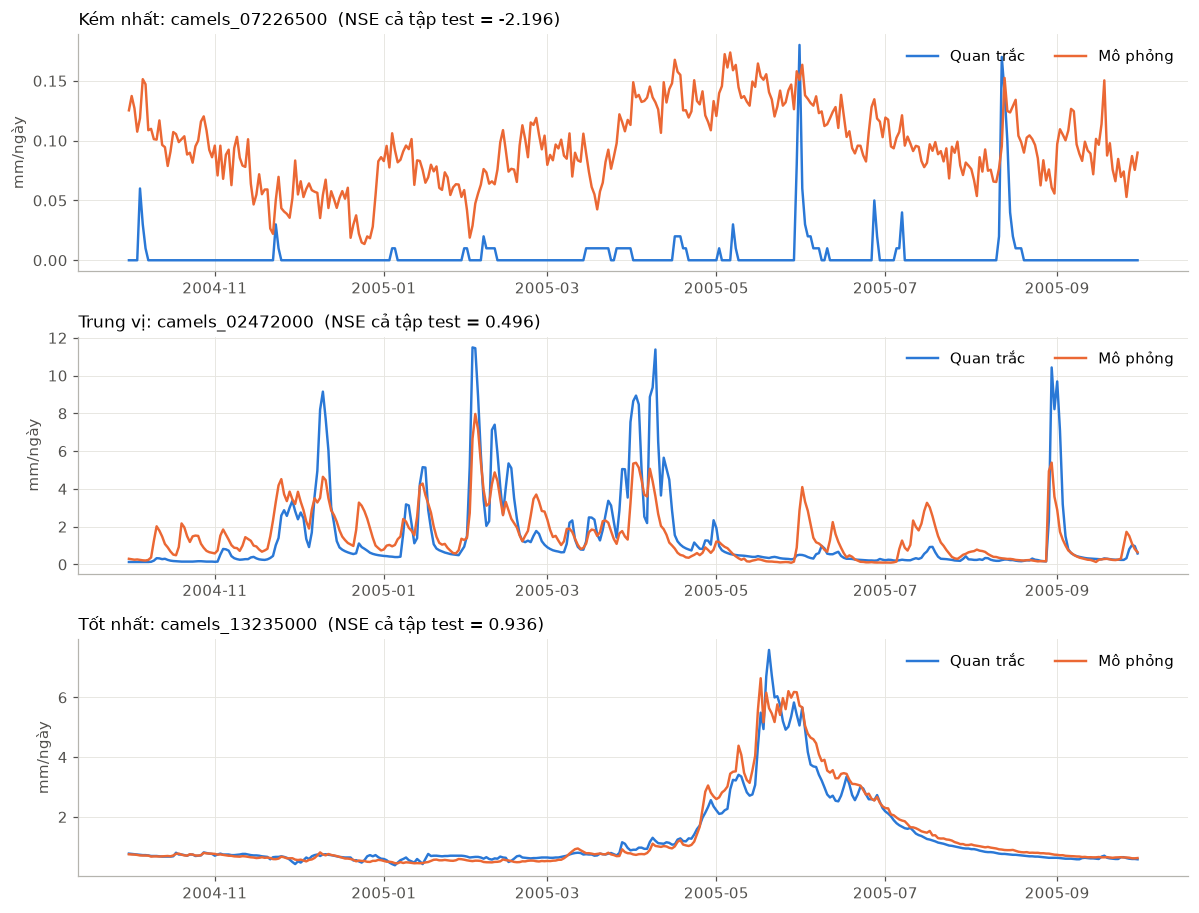

In [11]:
WATER_YEAR = 2005   # năm thủy văn 01/10/2004 -> 30/09/2005

def get_series(basin):
    xr_ = TEST_RESULTS[basin]["1D"]["xr"]
    obs = xr_[f"{TARGET}_obs"].isel(time_step=-1).to_series()
    sim = xr_[f"{TARGET}_sim"].isel(time_step=-1).to_series()
    # NeuralHydrology cắt giá trị mô phỏng âm về 0 khi tính metric (clip_targets_to_zero), nên ta cũng cắt khi vẽ
    return obs, sim.clip(lower=0)

ranked = nse.dropna().sort_values()
picks = {"Kém nhất": ranked.index[0], "Trung vị": ranked.index[len(ranked) // 2], "Tốt nhất": ranked.index[-1]}
start, end = f"{WATER_YEAR - 1}-10-01", f"{WATER_YEAR}-09-30"

fig, axes = plt.subplots(len(picks), 1, figsize=(11, 2.8 * len(picks)), sharex=False)
for ax, (label, basin) in zip(np.atleast_1d(axes), picks.items()):
    obs, sim = get_series(basin)
    ax.plot(obs.loc[start:end].index, obs.loc[start:end].values, color=C_BLUE, label="Quan trắc")
    ax.plot(sim.loc[start:end].index, sim.loc[start:end].values, color=C_ORANGE, label="Mô phỏng")
    ax.set_title(f"{label}: {basin}  (NSE cả tập test = {nse[basin]:.3f})", loc="left")
    ax.set_ylabel("mm/ngày")
    ax.legend(loc="upper right", ncol=2)
plt.tight_layout(); plt.savefig(E2_DIR / f"{EXPERIMENT}_hydrographs_WY{WATER_YEAR}.png", dpi=150); plt.show()